# Week 11: Final Report & Presentation
## TMI-102 | PaAC, IIT Roorkee
**Gurpreet Singh | IIT Roorkee**

*Finetuning DL Models on Astrophysical Datasets: frozen baseline vs full fine-tuning vs LoRA on 3-class Galaxy Zoo (elliptical, merger, spiral)*

## Part 1: Abstract

In order to study how galaxies form and evolve, we need to classify galaxies by shape, which is a key step in the study. Wide sky surveys produce a lot more images than humans can label by hand. For example, in this project, we use the Galaxy Zoo images, which had images labeled by hand because it was a competition where thousands of people participated to label these images. In real-life surveys, we get millions of images, which is not feasible to be labeled by hand.

In our example, we saw that mergers are rare, about three times fewer than the other two classes, elliptical and spiral, and also they have noisy labels. We need a method to do all this automatically on its own with little to no human intervention.

ResNet50 is a model which is pre-trained on ImageNet. We used it to train our own model by comparing it across three strategies:

* a frozen backbone with just a trained head
* full fine-tuning of the entire ResNet50 model
* LoRA (low-rank adapters), rank 4 on the head

In our training, we used class weights to compensate for the imbalance in the dataset we got from Galaxy Zoo. We tested LoRA using ranks 1, 2, 4, 8, and 16, and used GradCAM to see where the model actually looks in those images.

If we talk about the data, the split was as follows:

* Elliptical and spiral both had 5,692 images in their train dataset, 1,220 images in their validation dataset, and 1,220 images in their test dataset.
* Mergers had 1,520 images in its train dataset and 326 images in each validation and test dataset.

If we talk about the key results, the test accuracy for full fine-tuning was the highest, followed by frozen, then by LoRA. In trainable parameters, we had to train 99.96% fewer parameters in LoRA compared to the 24 million trainable parameters in full fine-tuning, but it lost 11 points of accuracy in this experiment.

The merger recall was 80.98% for full fine-tuning, 43.25% for frozen, and 37.42% for LoRA. Even rank ablations show no trend and zigzag between 79.93% and 83.33%, which means that rank was not the bottleneck for this.

The significance of this model is that updating the backbone of the originally gotten model from ResNet50 mattered more than the adapter size we were using. Rare merger classes and rare merger galaxies are actually the hard case. This is an important finding for scaling this approach for big surveys like the LSST.

## Part 2: Results Summary Figure

(A) training curves, (B) test accuracy, (C) Grad-CAM (full fine-tuning, one correct example per class), (D) LoRA rank ablation (single seed 42). Needs `histories_3class.json` and `gradcam_per_class.png` in the same folder.

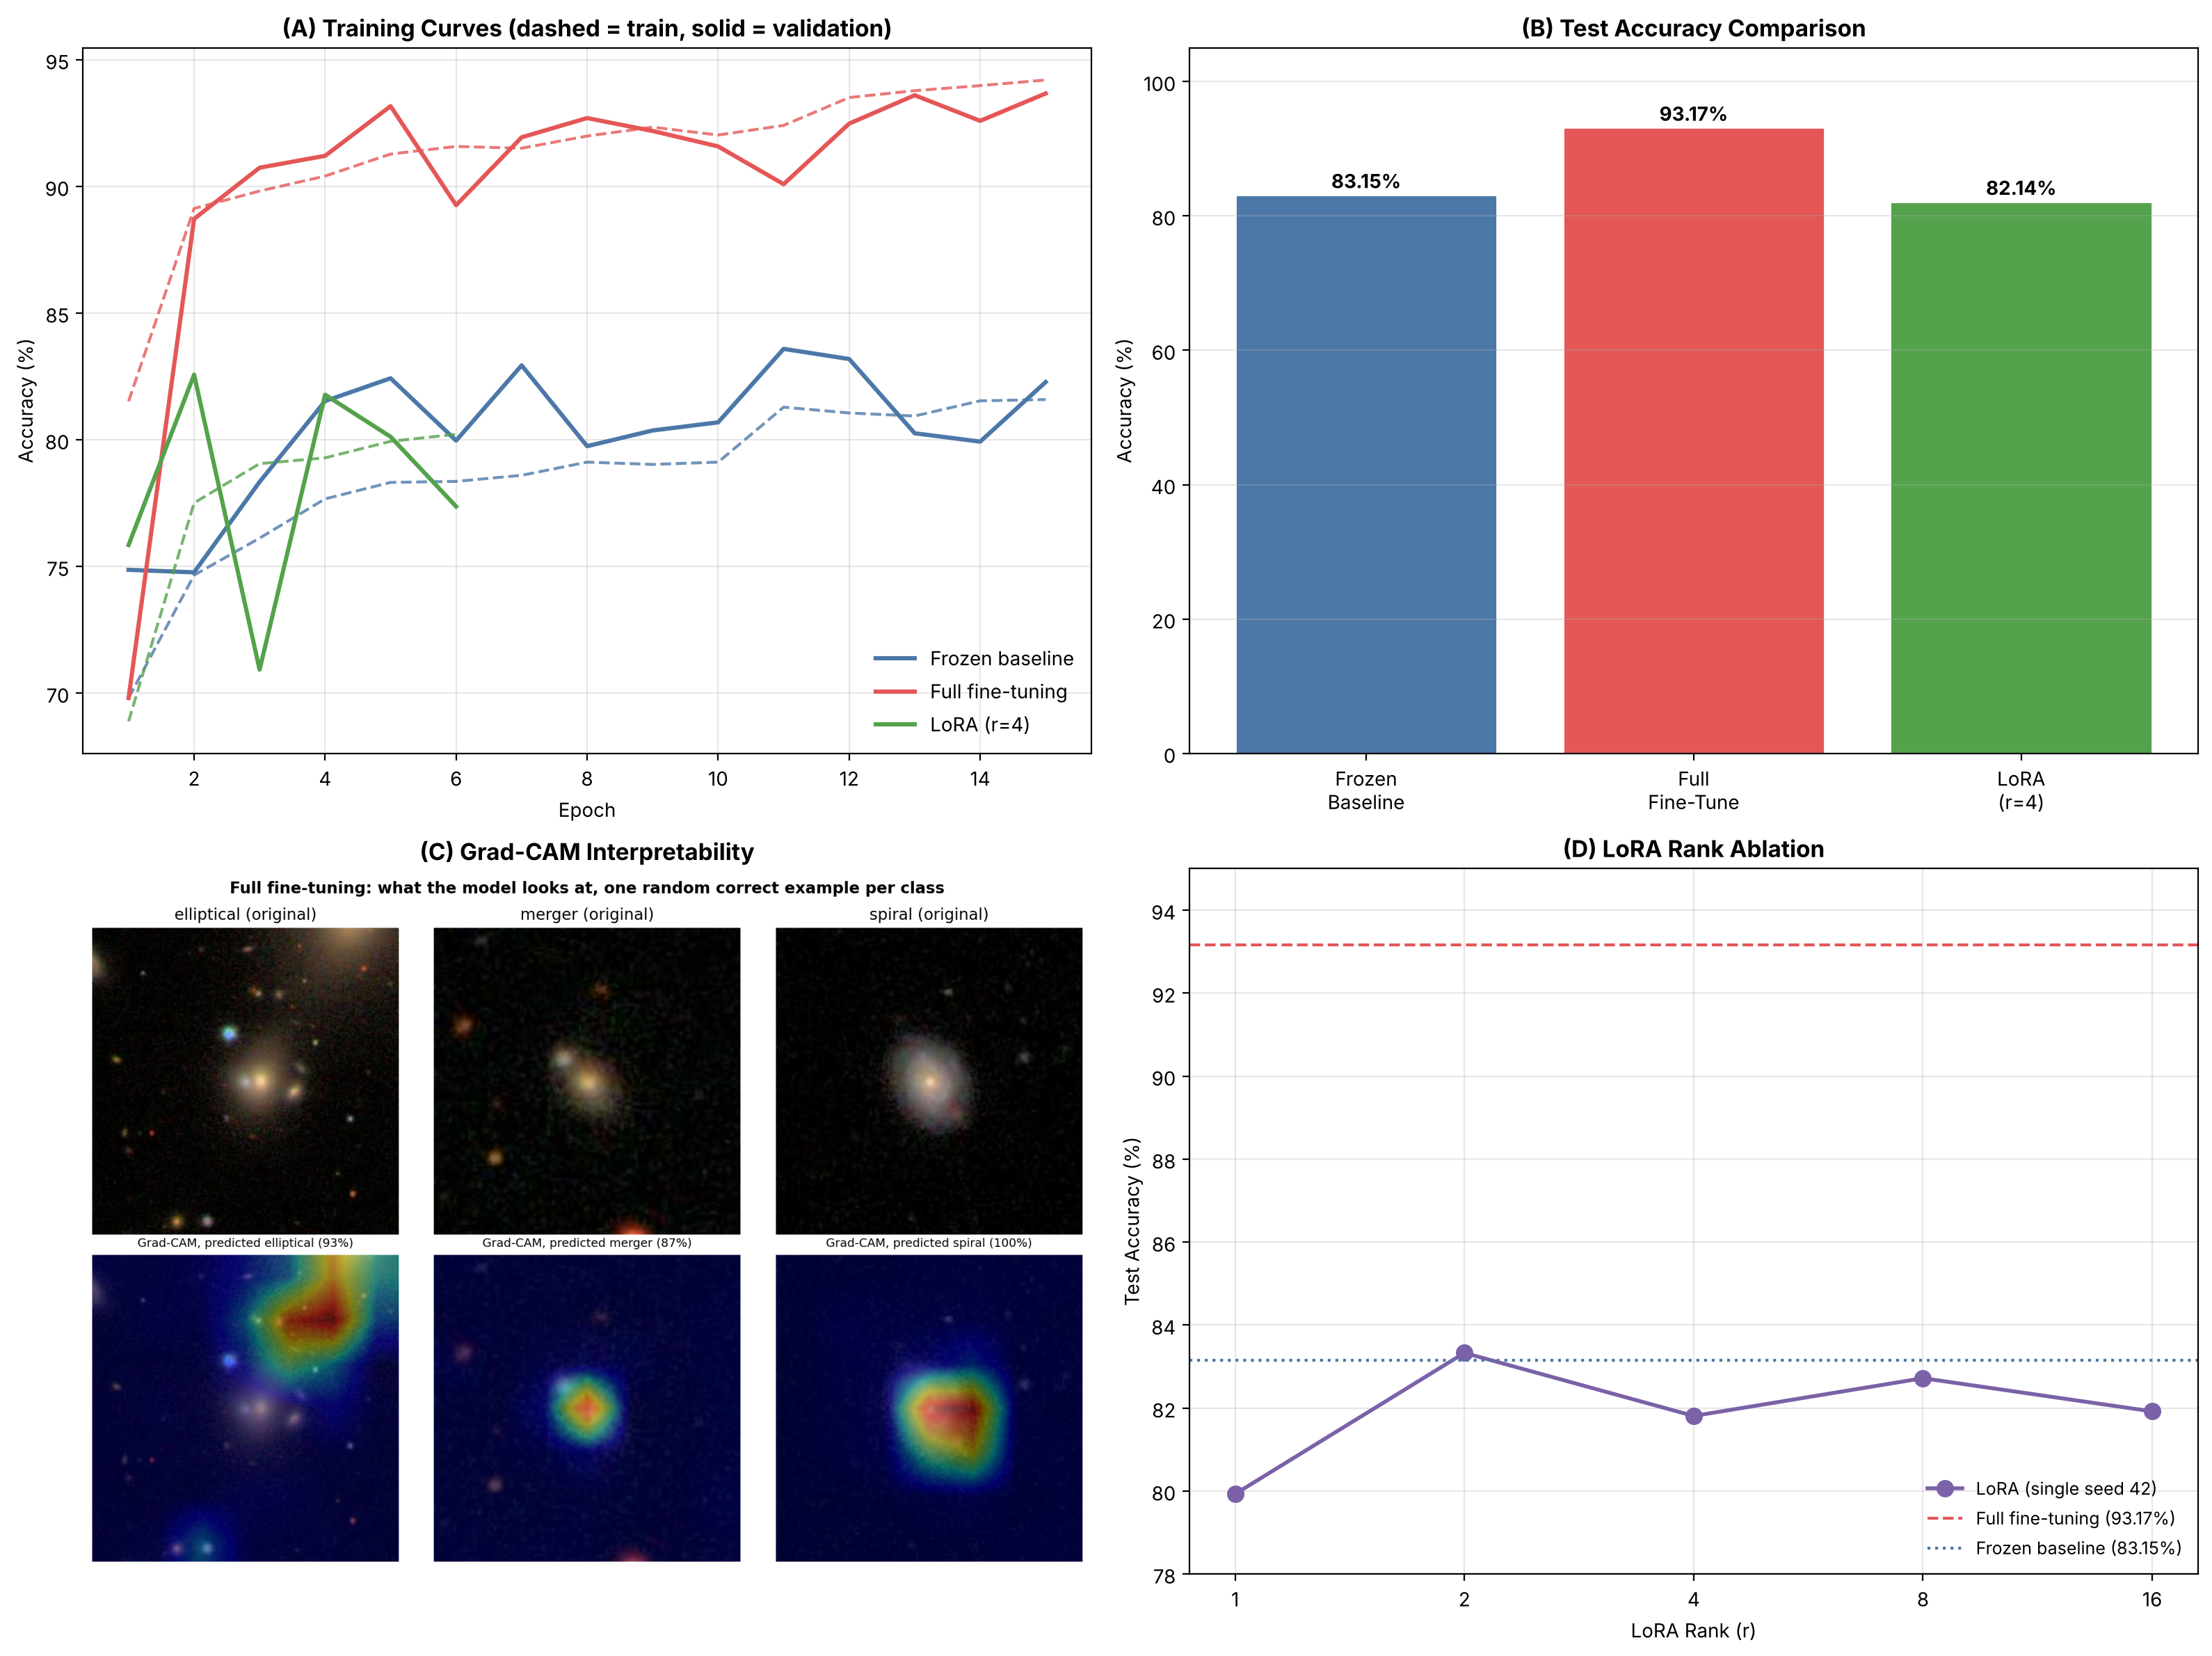

Summary figure saved as summary_figure_final.png


In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

h = json.load(open('histories_3class.json'))
col = {'frozen': '#4C78A8', 'full': '#E45756', 'lora': '#54A24B'}
lab = {'frozen': 'Frozen baseline', 'full': 'Full fine-tuning', 'lora': 'LoRA (r=4)'}
acc = {'frozen': 83.15, 'full': 93.17, 'lora': 82.14}          # test accuracy (%)
abl = [(1, 79.93), (2, 83.33), (4, 81.81), (8, 82.72), (16, 81.92)]  # rank ablation, seed 42

fig = plt.figure(figsize=(16, 12))

ax = fig.add_subplot(2, 2, 1)
for k in h:
    e = range(1, len(h[k]['val_acc']) + 1)
    ax.plot(e, [v * 100 for v in h[k]['acc']], color=col[k], ls='--', lw=1.5, alpha=.8)
    ax.plot(e, [v * 100 for v in h[k]['val_acc']], color=col[k], lw=2.2, label=lab[k])
ax.set_title('(A) Training Curves (dashed = train, solid = validation)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)'); ax.legend(frameon=False, loc='lower right'); ax.grid(alpha=.3)

ax = fig.add_subplot(2, 2, 2)
ks = ['frozen', 'full', 'lora']
bars = ax.bar(['Frozen\nBaseline', 'Full\nFine-Tune', 'LoRA\n(r=4)'], [acc[k] for k in ks],
              color=[col[k] for k in ks], edgecolor='white')
ax.set_ylim(0, 105); ax.set_ylabel('Accuracy (%)'); ax.set_title('(B) Test Accuracy Comparison', fontweight='bold')
for b, k in zip(bars, ks):
    ax.text(b.get_x() + b.get_width() / 2, acc[k] + 1, f'{acc[k]}%', ha='center', fontweight='bold')
ax.grid(alpha=.3, axis='y')

ax = fig.add_subplot(2, 2, 3)
ax.imshow(mpimg.imread('gradcam_per_class.png')); ax.axis('off')
ax.set_title('(C) Grad-CAM Interpretability', fontweight='bold')

ax = fig.add_subplot(2, 2, 4)
ax.plot([r for r, _ in abl], [a for _, a in abl], 'o-', color='#7B61A8', lw=2, ms=8, label='LoRA (single seed 42)')
ax.axhline(93.17, color=col['full'], ls='--', label='Full fine-tuning (93.17%)')
ax.axhline(83.15, color=col['frozen'], ls=':', label='Frozen baseline (83.15%)')
ax.set_xscale('log', base=2); ax.set_xticks([1, 2, 4, 8, 16]); ax.set_xticklabels(['1', '2', '4', '8', '16'])
ax.set_ylim(78, 95); ax.set_xlabel('LoRA Rank (r)'); ax.set_ylabel('Test Accuracy (%)')
ax.set_title('(D) LoRA Rank Ablation', fontweight='bold'); ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig('summary_figure_final.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print('Summary figure saved as summary_figure_final.png')


## Part 3: Comparison Table

| Metric | Frozen Baseline | Full Fine-Tune | LoRA (r=4) |
|:---|:---:|:---:|:---:|
| Trainable Parameters | 525,315 | 24,059,907 | 9,987 |
| Parameter Reduction (vs full FT) | 97.82% | 0% (reference) | 99.96% |
| Time per Epoch | 148 s | 167 s | 152 s |
| Training Epochs | 15 | 15 | 6 (best epoch 2) |
| Final Train Accuracy (best epoch) | 81.29% | 93.78% | 77.51% |
| Final Val Accuracy (best epoch) | 83.59% | 93.60% | 82.57% |
| **Final Test Accuracy** | **83.15%** | **93.17%** | **82.14%** |
| Test Loss | 0.4605 | 0.2037 | 0.4694 |
| Spiral F1 | 0.888 | 0.948 | 0.886 |
| Elliptical F1 | 0.873 | 0.962 | 0.859 |
| Merger F1 | 0.450 | 0.767 | 0.403 |
| Macro-Avg F1 | 0.737 | 0.892 | 0.716 |
| ROC AUC (weighted) | ~0.942 | ~0.990 | ~0.936 |

*Train/val accuracy are from the best epoch (early stopping restored it). Weighted AUC is computed from 3-decimal per-class AUCs (about ±0.001).*


## Part 4: Discussion Questions

**Q1.** What is the main takeaway of your project? If you had to summarize it in one sentence, what would it be?

*Your answer:*

Fine-tuning the backbone was seen more important than saving parameters using LoRa or frozen backbone. Because when we full fine-tuned our model, it reached 93.17% test accuracy, against 82 to 83% for the frozen and LoRa models. The gap was mainly seen in the rare merger class, where recall was 81% in full fine-tuning, compared with 43% and 37% for frozen and LoRa models.

---

**Q2.** In what real-world scenario would LoRA's parameter efficiency matter most? (Think: edge deployment, multi-task learning, compute budgets.)

*Your answer:*

In a real-world situation, LoRA's efficiency can be very helpful to a student or a small lab that is trying to do some quick experiments. They don't possess a big GPU to train different models for every single one of the tasks again and again in a reasonable time.

What they can do is utilize LoRA's efficiency, keep the backbone frozen, and use different LoRA adapters on the head for every single one of the tasks. For example, in mine, we had 24 million trainable parameters with full fine-tuning, whereas using LoRA, we had to train only 9,987 parameters, which is approximately 99.96% fewer parameters.

The cost was that accuracy reduced by 11 points, and it was seen that most of this loss was on the rare merger class. The recall dropped from 81% with full fine-tuning to 37% with LoRA. If someone can afford to lose some accuracy, they can go ahead with LoRA adapters rather than full fine-tuning all the models again and again.

---

**Q3.** What are the **limitations** of your study? List at least 3.

*Your answer:*

**1.** The LoRA was only trained on the head, and the backbone was kept frozen completely.

In our model, ResNet-50 had produced all the features, and a small head, a 256-unit layer, was added towards the end to make the final decision. LoRA's low-rank adapter was only in that one 256-unit layer. The backbone, which held approximately 23.5 million of the total 24 million weights, never changed in our LoRA run. Only 9,987 parameters were trained in that LoRA run.

On the other hand, full fine-tuning updates the whole backbone, so it can change how the backbone extracts features from galaxy images. That is a likely reason why LoRA got only 82.14% accuracy and full fine-tuning got 93.17%.

Our results don't show that LoRA is weak for these tasks, but the comparison is not like-for-like. It would have been a better and fairer comparison if LoRA was put inside the ResNet layers too, because right now the LoRA adapter had very little to adapt for. Even the base weight of the end layer was taken as random and frozen. It was not even pre-trained.

LoRA (82.14%) also scored slightly below the frozen baseline (83.15%), which shows the adapter added almost nothing over the frozen head.

**2.** The second point is that rank ablation is basically noise level. We only used one seed, that is, 42, to train our model. I trained LoRA again with ranks 1, 2, 4, 8, and 16, all of them once with seed 42. What I found was that there were no steady climbs or clear peaks, as in a real-world effect. Instead, I found zigzags: it was best at rank 2 with 83.33%, and rank 16 was even lower than rank 8. When we repeated rank 4, the accuracy changed from 82.14% to 81.81%, a difference of about 0.3 points, with nothing else changed.

Since we have been using one seed for every run, it is kind of random. To reduce this randomization, we should train each rank with multiple seeds and average the accuracies, so we can report a mean and spread, so that the comparison between ranks is reliable rather than based on a single random run. In all this, the merger recall rose from 40.8% at rank 1 to 58.3% at rank 16, but it was still far below the full fine-tuning recall, which was 80.98%.

**3.** My test set had 2,766 images, out of which only 326 were mergers. Each merger class came out to be around 0.3% of that class's recall, which means that even a few wrong interpretations of the galaxies will move the score a lot.

Galaxy Zoo labels are not hard truth. They comprise the vote fractions from volunteers who participated in that. We turn them into hard classes using cutoffs. For example, we chose a minimum confidence of 0.8 for elliptical and spiral, while for mergers I chose 0.3.

Galaxies near the cutoff are genuinely ambiguous, since some mistakes may be just label noise. In the GradCam wrong predictions example, we could clearly see that confident predictions, for example, a merger class predicted as spiral at 95%, fit this explanation. The fact that the merger class is small also hurts the metrics. The merger recall was 43.25% in frozen, 80.98% in full fine-tuning, and 37.42% in LoRA, while the other two classes, elliptical and spiral, stayed above 85% all the time.

The class weights help with the imbalance during training so that the classes don't have much imbalance in the number of images in the dataset, but obviously this can't fix the noisy labels.

**4.** The fourth limitation that we faced is regarding early stopping and short training in LoRA. Early stopping watched the validation loss and restored the best epoch weights, which is good for avoiding overfitting, but it can stop a little too early.

For example, LoRA stopped at epoch 6, with its best epoch at epoch 2. The validation accuracy curve for LoRA was jumpy. It was around 83% at epoch 2 and just 71% at epoch 3, a drop of about 12 percentage points. There is a high chance that this best point at epoch 2 was just luck.

Due to this, the LoRA numbers can mean undertrained rather than converged and limited. Frozen and full fine-tune versions ran the complete 15 epochs. The ablation also used a different approach for this. It ran for 12 epochs with a patience of 4, so it is actually not perfectly comparable with the main runs that we ran earlier. A fair fix that could be done to this would be to run the same schedule for all the methods, plus a lower learning rate or longer patience for LoRA.

---

**Q4.** If you had 4 more weeks, what would you add to this project? List 3 extensions.

*Your answer:*

If I had got 4 extra weeks on this project, I would love to do the 4 things mentioned below.

**1.** I would put LoRA adapters inside the ResNet layers. Right now, as mentioned above, they only touch the 256-unit head at the end, so only 9,987 parameters are trained, and the backbone never gets changed. The extension would be to put low-rank adapters into the ResNet-50 convolution itself, or maybe some last block layers, and keep those weights pre-trained and frozen.

This will test the real LoRA question: Can small adapters, which are put inside the backbone, get close to the accuracy that full fine-tuning provides us with, with a lot fewer parameters than we train in full fine-tuning? That is 24 million trainable parameters. It will also fix limitation 1 that we faced in this project, since the adapters have pre-trained weights to adapt. It would also let the backbone's own features change, instead of only the head adapting on top of fixed features.

I don't know what the outcome of this will be, but it is an experiment that I would really love if I had more weeks on this project.

**2.** The second thing I would like to do in the extra weeks is that I would train the same models with several seeds per rank. Right now, as I mentioned above, we are just training for each rank once with seed 42, which is giving zigzag results between 79.93% and 83.33%.

The extension would be to run each rank with at least 5 seeds and report the final result with a ± standard deviation. This will show whether any rank difference is actually real or whether it is just noise, like the 0.3-point rank 4 repeat difference we measured. It is also simple, needing no new code other than a loop to change the seeds, though it needs more compute time, and it will also fix the second limitation that we faced.

**3.** Right now, in the current model, the merger class is the weakest class that we have encountered, since its labels come from a cutoff of just 0.3.

The extension would be to test different cutoffs, or use soft labels, training on the vote fractions instead of just hard classes that we made from them. Another option would be to use more merger images and stronger augmentation. This will target our limitation 3 that we had been facing, where label noise and small classes both hurt the model significantly.

**4.** The fourth extension that I would like to do is this: since we are just training on three classes right now (elliptical, merger, and spiral), I would really love to add more classes to this model. Galaxy Zoo already has more morphological categories which we can work on. Also, we have Galaxy Zoo 2 with 37 morphological features.

In simple words, the extension would be to move to more classes or a multi-label setup, since a single galaxy can have multiple features at once. This will help us see whether our model holds up on a harder, finer-grain problem or not. We can expect new problems, like more class imbalance or more ambiguous labels, and a possible need for per-class metrics instead of just accuracy. It would be really fun, interesting, and educational to work on more galaxy types and figure out how things actually work.

---

**Q5.** How would you adapt this pipeline for the Vera Rubin Observatory's LSST survey (10 billion galaxies, 60 PB of data)?

*Your answer:*

In order to adapt our trained pipeline for the LSST survey, we would need to work around a few things, since the data, as mentioned in the assignment, is far more than what we trained our current model on. Even in full fine-tuning, we only had 24 million parameters at 93.17% accuracy, while putting LoRA at the head gave us fewer parameters to train, but at the accuracy cost of losing 11 points. Small adapters are cheap to store and train again and again, and they can be swapped per survey or any filter if we want.

In order to try to get higher accuracy using LoRA, we can use the extension mentioned in the answer to question 4, which is putting LoRA adapters inside the backbone, not just the head. The LSST images actually differ from what we trained our model on: the different depths, resolution, filters, and seeing conditions. Before we trust the model that we already trained on the Galaxy Zoo dataset, we should check its performance on a small sample from the LSST images, and fine-tune or adapt it based on the performance it gives.

In our Galaxy Zoo dataset, the galaxies were labeled, but we can't hand-label billions of galaxies, as mentioned in the assignment, so we need to use a small labeled set. Then use active learning, where the model will ask humans to label only the uncertain galaxies. Plus, citizen science labels like Galaxy Zoo can also be used in it.

We could see that mergers were the weakest class in the model we trained, which was 43.25% for frozen, 80.98% for full fine-tuning, and 37.42% for LoRA. When we scale it to billions of galaxies, this means that, in absolute numbers, many more rare galaxies will be missed. Having a track of per-class recall would be better than going for the overall accuracy.

Also, right now, the model doesn't ask for a human or a follow-up review if it detects some low-confidence galaxies. What we can do is that it should output the confidence and send low-confidence galaxies for human reviews. This can clearly be seen in the grad cam wrong prediction examples, since it made confident mistakes. It predicted a merger galaxy as a spiral with a confidence of 95%.

## Part 5: Presentation Outline

| Slide # | Title | Content (2-3 bullets) | Time |
|:---:|:---|:---|:---:|
| 1 | Title | Finetuning DL Models on Astrophysical Datasets; Gurpreet Singh, 26323018; TMI-102, PaAC | 30s |
| 2 | Motivation | Galaxy shape shows how galaxies evolve; surveys give far more images than humans can label; need automatic classification | 1m |
| 3 | Dataset | Galaxy Zoo, 3 classes (elliptical, merger, spiral); elliptical/spiral 5692/1220/1220, merger 1520/326/326 (train/val/test); merger about 3x rarer so class weights | 1m |
| 4 | Approach | ResNet-50 (ImageNet) with 3 strategies: frozen, full fine-tuning, LoRA r=4 on the head; early stopping | 1.5m |
| 5 | LoRA Explained | Frozen W plus low-rank update (A, B) scaled by alpha/r; 9,987 trainable parameters (99.96% fewer than full fine-tuning) | 1.5m |
| 6 | Results Table | Test accuracy 83.15 / 93.17 / 82.14%; macro-F1 0.737 / 0.892 / 0.716; test loss 0.4605 / 0.2037 / 0.4694 | 1m |
| 7 | Training Curves | Panel A: full fine-tuning highest; LoRA stopped at epoch 6 (best epoch 2) with a jumpy validation curve | 1m |
| 8 | The Merger Problem | Merger recall 43.25 / 80.98 / 37.42% (frozen / full / LoRA); elliptical and spiral stay high | 1m |
| 9 | Grad-CAM | Where the model looks, one example per class; the elliptical example highlights a bright object off-centre although the prediction was correct; confident wrong predictions exist | 1.5m |
| 10 | LoRA Rank Ablation | Ranks 1, 2, 4, 8, 16 give 79.93-83.33% with no trend (one seed); rank 4 repeat 82.14% vs 81.81% | 1m |
| 11 | Robustness | Week 8 test on the full fine-tuned model (300 images, 100 per class): clean 85.7%; noise σ=0.05 gives 79.7% and σ=0.20 gives 38.7% (near chance); blur holds up to σ=2.0 (88.7%) and falls to 73.0% at σ=3.0, mainly spiral (44%); at high noise the model collapses to "merger" (227 of 300 predictions) | 1m |
| 12 | Demo | Live web demo on GitHub Pages: https://neogurpreet-dev.github.io/TMI102-Finetuning-DL-Models/ | 1.5m |
| 13 | Conclusions | Backbone updates mattered more than adapter size; limitations; 4 extensions; LSST adaptation | 1.5m |
| 14 | Questions | Q&A | n/a |

*Talk time about 14-15 min.*

---

### Final Submission Checklist
- [x] Abstract
- [x] Summary figure
- [x] Results table
- [x] Q1-Q5
- [x] Presentation outline 
- [x] Clean notebook named `Week_11_Gurpreet_26323018.ipynb`
- [x] GitHub repo with README, notebooks, web demo
- [x] Live GitHub Pages URL
